In [4]:
import pandas as pd
from db_queries import get_location_metadata
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import numpy as np
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import yaml

# Set paths ####################################################################
RAW_DATA_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/training_data/2026_09_13.01/data.parquet"
GBD_FILE = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/gbd_prevalence/gbd_mean_neonatal_mortality_prevalence.parquet"
INFERENCE_FILE_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_14.01/ssp245.parquet"  # Consumption merged on birth year
RESULTS_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_14.02/"  # .01 is the input spec; .02 is the fit

RESULTS_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_21.02/"
RESULTS_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_22.02/"
RESULTS_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.02/"  # birth_year dropped, consumption_median_RT rescaled to $/day

INFERENCE_FILE_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.01/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
INFERENCE_FILE_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.02/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
INFERENCE_FILE_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.01/ssp245.parquet"  # model 2026_09_23.02: consumption_median_RT (LDI based), no birth_year

PLOT_OUTPUT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/"


df_raw = pd.read_parquet(RAW_DATA_PATH)

# Add location names
locs = get_location_metadata(location_set_id=39, release_id=16)

df_raw = df_raw.merge(
    locs[["location_id", "location_name", "level", "super_region_name"]],
    on="location_id",
    how="left",
)

df_raw.head()

,year_start,year_end,nid,survey_name,int_year,int_month,sex_id,mothers_age_year,aod_months,age_month,...,year_id,age_group_id,int_birth_year_diff_months,log_consumption_pd,sdi,consumption_pd_national_median,consumption_median_RT,location_name,level,super_region_name
0,2009,2010,13109,DHS_MIS,None,None,2,None,0,0,...,2009,42,0,-0.245692,0.318291,2.179549,2.361256,Uganda,3,Sub-Saharan Africa
1,2022,2022,538795,None,2022,5,2,18,0,0,...,2021,42,11,1.312609,0.447416,3.220460,3.404259,United Republic of Tanzania,3,Sub-Saharan Africa
2,2017,2017,353526,None,2017,4,1,20,0,0,...,2017,42,0,2.448691,0.373539,3.087602,4.210878,Senegal,3,Sub-Saharan Africa
3,2019,2021,467681,DHS,None,None,1,None,0,0,...,2020,42,2,1.619791,0.583046,4.671741,5.111802,India,3,South Asia
4,2000,2000,19156,None,2000,2,2,24,0,0,...,1999,42,2,-0.227447,0.340183,1.772798,2.106530,Cambodia,3,"Southeast Asia, East Asia, and Oceania"


In [10]:
# Parametric fixed effects, compared across model runs #######################
# base_model_coefs.parquet holds only the parametric terms. A spline on
# consumption_pd is not in there - its partial effect lives in
# spline_effect_consumption_pd.parquet - so these tables are exactly the
# non-spline fixed effects.
#
# A run that has not finished yet is skipped with a note rather than raising,
# so the fourth slot can be filled in by pointing RESULTS_09_23 at the run and
# re-executing once it lands.
COEF_MODELS = {
    "RESULTS_09_14": RESULTS_09_14,
    "RESULTS_09_21": RESULTS_09_21,
    "RESULTS_09_22": RESULTS_09_22,
    "RESULTS_09_23": RESULTS_09_23,
}
COEF_COLUMNS = ["term", "Estimate", "std_error", "p_value", "signif"]

coef_tables = {}
_coef_long = []
for _name, _path in COEF_MODELS.items():
    _dir = Path(_path)
    if not (_dir / "base_model_coefs.parquet").exists():
        print(f"{_name}: no base_model_coefs.parquet yet at {_dir}\n")
        continue

    _spec = yaml.safe_load((_dir / "specification.yaml").read_text())
    _tab = pd.read_parquet(_dir / "base_model_coefs.parquet").reset_index()
    _tab["signif"] = pd.cut(
        _tab["p_value"],
        bins=[-0.001, 0.001, 0.01, 0.05, 1.0],
        labels=["***", "**", "*", ""],
    ).astype(str)
    _tab = _tab[COEF_COLUMNS].round({"Estimate": 5, "std_error": 5, "p_value": 4})

    _ranef = pd.read_parquet(_dir / "base_model_ranef.parquet")
    _splines = [p["name"] for p in _spec["predictors"] if p.get("spline")]
    print(
        f"{_name}  ({_dir.name}): {len(_tab)} parametric fixed effects; "
        f"training data {_spec['version']['training_data']}\n"
        f"  spline terms not shown: {', '.join(_splines) if _splines else 'none'}\n"
        f"  random intercept on ihme_loc_id: {len(_ranef)} countries, "
        f"sd {_ranef['offset'].std():.4f}, "
        f"range {_ranef['offset'].min():+.3f} to {_ranef['offset'].max():+.3f}"
    )
    display(_tab)
    print()

    coef_tables[_name] = _tab
    _coef_long.append(_tab.assign(model=_name))

# Side by side, so a term can be read across runs. Terms that a run did not
# include come back NaN, which is the point: it shows what entered when.
coef_compare = (
    pd.concat(_coef_long)
    .pivot(index="term", columns="model", values=["Estimate", "p_value", "signif"])
    .swaplevel(axis=1)
    .reindex(
        columns=pd.MultiIndex.from_product(
            [list(coef_tables), ["Estimate", "p_value", "signif"]]
        )
    )
)
print(f"Estimates across {len(coef_tables)} runs:")
coef_compare

RESULTS_09_14  (2026_09_14.02): 3 parametric fixed effects; training data 2026_09_13.01
  spline terms not shown: consumption_pd
  random intercept on ihme_loc_id: 60 countries, sd 0.3961, range -1.442 to +0.606


,term,Estimate,std_error,p_value,signif
0,(Intercept),33.15694,1.55841,0.0,***
1,C(sex_id)2,-0.26264,0.00905,0.0,***
2,birth_year,-0.01827,0.00077,0.0,***



RESULTS_09_21  (2026_09_21.02): 4 parametric fixed effects; training data 2026_09_13.01
  spline terms not shown: consumption_pd
  random intercept on ihme_loc_id: 60 countries, sd 0.3877, range -1.416 to +0.610


,term,Estimate,std_error,p_value,signif
0,(Intercept),31.86277,2.05290,0.0000,***
1,C(sex_id)2,-0.26266,0.00905,0.0000,***
2,birth_year,-0.01760,0.00104,0.0000,***
3,consumption_pd_national_median,-0.03904,0.04034,0.3332,



RESULTS_09_22  (2026_09_22.02): 3 parametric fixed effects; training data 2026_09_13.01
  spline terms not shown: consumption_pd
  random intercept on ihme_loc_id: 60 countries, sd 0.3452, range -0.997 to +0.637


,term,Estimate,std_error,p_value,signif
0,(Intercept),-2.96831,0.07954,0.0,***
1,C(sex_id)2,-0.26259,0.00905,0.0,***
2,consumption_pd_national_median,-0.49452,0.03009,0.0,***



RESULTS_09_23  (2026_09_23.02): 3 parametric fixed effects; training data 2026_09_13.01
  spline terms not shown: consumption_pd
  random intercept on ihme_loc_id: 60 countries, sd 0.3725, range -1.089 to +0.603


,term,Estimate,std_error,p_value,signif
0,(Intercept),-2.80158,0.08316,0.0,***
1,C(sex_id)2,-0.26257,0.00905,0.0,***
2,consumption_median_RT,-0.57601,0.02903,0.0,***



Estimates across 4 runs:


RESULTS_09_14                RESULTS_09_21  \
                                    Estimate p_value signif      Estimate   
term                                                                        
(Intercept)                         33.15694     0.0    ***      31.86277   
C(sex_id)2                          -0.26264     0.0    ***      -0.26266   
birth_year                          -0.01827     0.0    ***       -0.0176   
consumption_median_RT                    NaN     NaN    NaN           NaN   
consumption_pd_national_median           NaN     NaN    NaN      -0.03904   

                                              RESULTS_09_22                 \
                               p_value signif      Estimate p_value signif   
term                                                                         
(Intercept)                        0.0    ***      -2.96831     0.0    ***   
C(sex_id)2                         0.0    ***      -0.26259     0.0    ***   
birth_year                         0.0    ***           NaN     NaN    NaN   
consumption_median_RT              NaN    NaN           NaN     NaN    NaN   
consumption_pd_national_median  0.3332             -0.49452     0.0    ***   

                               RESULTS_09_23                 
                                    Estimate p_value signif  
term                                                         
(Intercept)                         -2.80158     0.0    ***  
C(sex_id)2                          -0.26257     0.0    ***  
birth_year                               NaN     NaN    NaN  
consumption_median_RT               -0.57601     0.0    ***  
consumption_pd_national_median           NaN     NaN    NaN

4,562 cells, 60 countries, 1,711,538 births

correlation between regressors, within country:
            log_med  birth_year  log_cons
log_med       1.000       0.554     0.190
birth_year    0.554       1.000     0.142
log_cons      0.190       0.142     1.000

variance inflation factors (within country):
      term   VIF  R2_on_others
   log_med 1.469         0.319
birth_year 1.446         0.308
  log_cons 1.039         0.038
  rule of thumb: VIF > 5 is worth noting, > 10 is severe. condition number 1.9

coefficient path for log(national median):
                  model    coef     se      p  ci_low  ci_high  se_vs_first
                  alone -0.3095 0.0794 0.0001 -0.4651  -0.1539       0.6223
           + country FE -0.6584 0.1276 0.0000 -0.9084  -0.4083       1.0000
           + birth_year -0.1875 0.1293 0.1469 -0.4409   0.0658       1.0134
+ household consumption -0.0246 0.1714 0.8856 -0.3606   0.3113       1.3434

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_mal

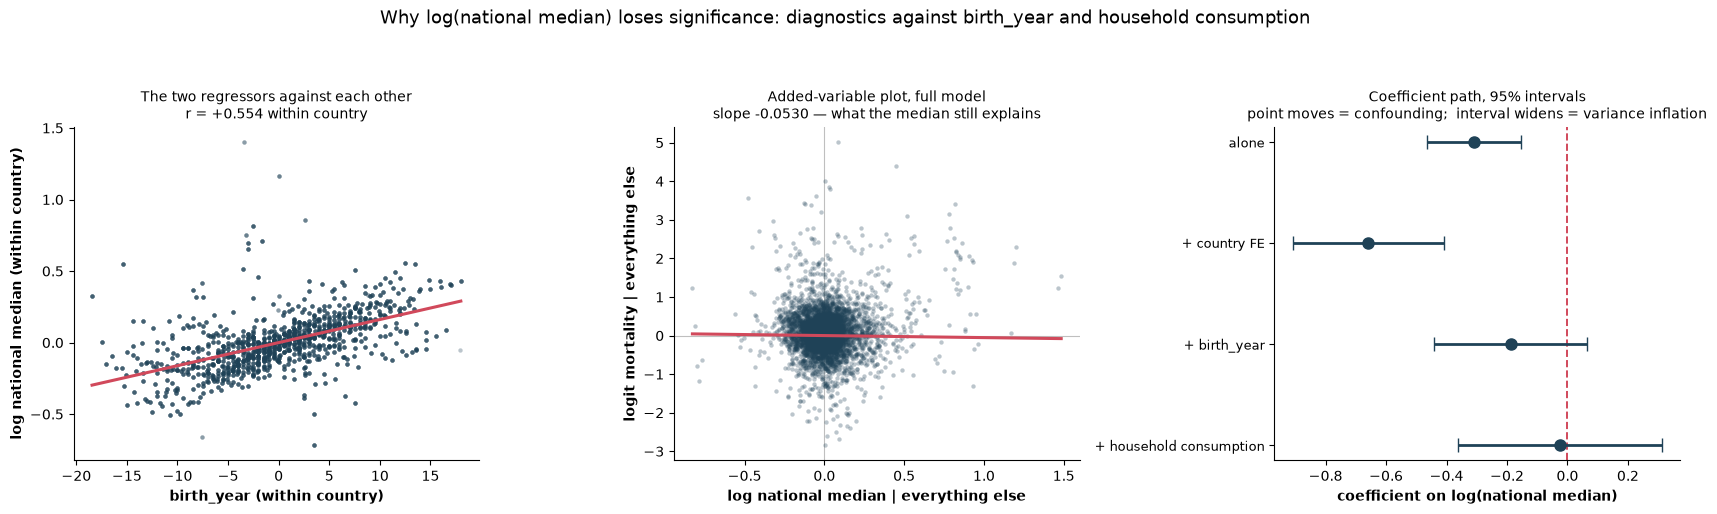

In [11]:
# Are consumption_pd_national_median and birth_year collinear? ###############
# Standard diagnostics for why the national median lost significance once
# birth_year and the household consumption term entered the model.
#
# Worked on country x birth_year x wealth-quintile cells rather than on the
# 1.7m individual births: the binomial likelihood is identical, and it makes
# the design small enough to compute VIFs and added-variable plots on. The
# country random intercept is replaced by country fixed effects, which is the
# conservative choice for a collinearity question because it removes all
# between-country variation and leaves only the within-country variation the
# terms actually compete over.
#
# The three panels are the three standard views:
#   left   - the raw collinearity: the two regressors against each other,
#            within country
#   middle - the added-variable (partial regression) plot for the median: what
#            is left of it, and of the outcome, once everything else is
#            partialled out. A flat cloud means nothing remains to explain.
#   right  - the coefficient path across nested models, with 95% intervals.
#            Watch whether the INTERVAL widens (variance inflation) or the
#            POINT moves (confounding). They have different remedies.
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

CO_QUINTILES = np.linspace(0, 1, 6)
CO_TERM = "log_med"

_co = df_raw[
    (df_raw["consumption_pd"] > 0) & (df_raw["consumption_pd_national_median"] > 0)
].dropna(subset=["unweighted_population_percentile", "neonatal_mortality"])
_co = _co.assign(
    _q=pd.cut(
        _co["unweighted_population_percentile"], bins=CO_QUINTILES, include_lowest=True
    )
)
co = (
    _co.groupby(["ihme_loc_id", "birth_year", "_q"], observed=True)
    .agg(
        deaths=("neonatal_mortality", "sum"),
        n=("neonatal_mortality", "size"),
        cons=("consumption_pd", "mean"),
        med=("consumption_pd_national_median", "first"),
    )
    .reset_index()
)
co = co[co["n"] > 0].copy()
co["surv"] = co["n"] - co["deaths"]
co["log_med"] = np.log(co["med"])
co["log_cons"] = np.log(co["cons"])
# Haldane-Anscombe, so zero-death cells survive the logit for the AV plot
co["logit_rate"] = np.log(
    ((co["deaths"] + 0.5) / (co["n"] + 1)) / (1 - (co["deaths"] + 0.5) / (co["n"] + 1))
)

print(
    f"{len(co):,} cells, {co['ihme_loc_id'].nunique()} countries, "
    f"{int(co['n'].sum()):,} births"
)

# 1. Correlation and VIF, within country #####################################
_terms = ["log_med", "birth_year", "log_cons"]
within = co.copy()
for c in _terms + ["logit_rate"]:
    within[c] = within[c] - within.groupby("ihme_loc_id")[c].transform("mean")

print("\ncorrelation between regressors, within country:")
print(within[_terms].corr().round(3).to_string())

_X = sm.add_constant(within[_terms].to_numpy())
vif = pd.DataFrame(
    {
        "term": _terms,
        "VIF": [variance_inflation_factor(_X, i + 1) for i in range(len(_terms))],
    }
)
vif["R2_on_others"] = 1 - 1 / vif["VIF"]
print("\nvariance inflation factors (within country):")
print(vif.round(3).to_string(index=False))
print(
    f"  rule of thumb: VIF > 5 is worth noting, > 10 is severe. "
    f"condition number {np.linalg.cond(within[_terms] / within[_terms].std()):.1f}"
)

# 2. Nested models: does the interval widen, or the point move? ##############
CO_MODELS = [
    ("alone", "deaths + surv ~ log_med"),
    ("+ country FE", "deaths + surv ~ log_med + C(ihme_loc_id)"),
    ("+ birth_year", "deaths + surv ~ log_med + C(ihme_loc_id) + birth_year"),
    (
        "+ household consumption",
        "deaths + surv ~ log_med + C(ihme_loc_id) + birth_year + log_cons",
    ),
]
_rows = []
for label, formula in CO_MODELS:
    m = smf.glm(formula, data=co, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": co["ihme_loc_id"]}
    )
    _rows.append(
        {
            "model": label,
            "coef": m.params[CO_TERM],
            "se": m.bse[CO_TERM],
            "p": m.pvalues[CO_TERM],
        }
    )
co_path = pd.DataFrame(_rows)
co_path["ci_low"] = co_path["coef"] - 1.96 * co_path["se"]
co_path["ci_high"] = co_path["coef"] + 1.96 * co_path["se"]
co_path["se_vs_first"] = co_path["se"] / co_path["se"].iloc[1]
print("\ncoefficient path for log(national median):")
print(co_path.round(4).to_string(index=False))

# 3. Added-variable plot pieces ##############################################
# Partial everything else out of both the outcome and the term, weighted by
# births, then regress one residual on the other: the slope IS the multiple
# regression coefficient.
_other = "logit_rate ~ C(ihme_loc_id) + birth_year + log_cons"
_res_y = smf.wls(_other, data=co, weights=co["n"]).fit().resid
_res_x = (
    smf.wls(
        "log_med ~ C(ihme_loc_id) + birth_year + log_cons", data=co, weights=co["n"]
    )
    .fit()
    .resid
)
_av_slope = np.polyfit(_res_x, _res_y, 1, w=np.sqrt(co["n"]))[0]

fig, axes = plt.subplots(ncols=3, figsize=(17, 5.2))

ax = axes[0]
ax.scatter(
    within["birth_year"],
    within["log_med"],
    s=10,
    alpha=0.3,
    color="#1f4257",
    linewidths=0,
    zorder=2,
)
_r = within[["birth_year", "log_med"]].corr().iloc[0, 1]
_fit = np.polyfit(within["birth_year"], within["log_med"], 1)
_xs = np.linspace(within["birth_year"].min(), within["birth_year"].max(), 50)
ax.plot(_xs, np.polyval(_fit, _xs), color="#d1495b", lw=2.2, zorder=3)
ax.set_xlabel("birth_year (within country)", fontweight="bold")
ax.set_ylabel("log national median (within country)", fontweight="bold")
ax.set_title(
    f"The two regressors against each other\nr = {_r:+.3f} within country", fontsize=10
)

ax = axes[1]
ax.scatter(_res_x, _res_y, s=10, alpha=0.3, color="#1f4257", linewidths=0, zorder=2)
_xs = np.linspace(_res_x.min(), _res_x.max(), 50)
ax.plot(_xs, _av_slope * _xs, color="#d1495b", lw=2.2, zorder=3)
ax.axhline(0, color="0.75", lw=0.8, zorder=1)
ax.axvline(0, color="0.75", lw=0.8, zorder=1)
ax.set_xlabel("log national median | everything else", fontweight="bold")
ax.set_ylabel("logit mortality | everything else", fontweight="bold")
ax.set_title(
    f"Added-variable plot, full model\nslope {_av_slope:+.4f} — what the median "
    "still explains",
    fontsize=10,
)

ax = axes[2]
_y = np.arange(len(co_path))
ax.errorbar(
    co_path["coef"],
    _y,
    xerr=1.96 * co_path["se"],
    fmt="o",
    color="#1f4257",
    ms=8,
    capsize=5,
    lw=2,
    zorder=3,
)
ax.axvline(0, color="#d1495b", lw=1.4, ls="--", zorder=2)
ax.set_yticks(_y, co_path["model"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("coefficient on log(national median)", fontweight="bold")
ax.set_title(
    "Coefficient path, 95% intervals\npoint moves = confounding;  "
    "interval widens = variance inflation",
    fontsize=10,
)

for ax in axes:
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.suptitle(
    "Why log(national median) loses significance: diagnostics against birth_year "
    "and household consumption",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0, 1, 0.92))

plot_path = f"{PLOT_OUTPUT}national_median_collinearity.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"\nSaved {plot_path}")
plt.show()

9,870 country-years across 470 countries, 2000-2020, 5 series
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/predictions_four_runs_three_countries.pdf


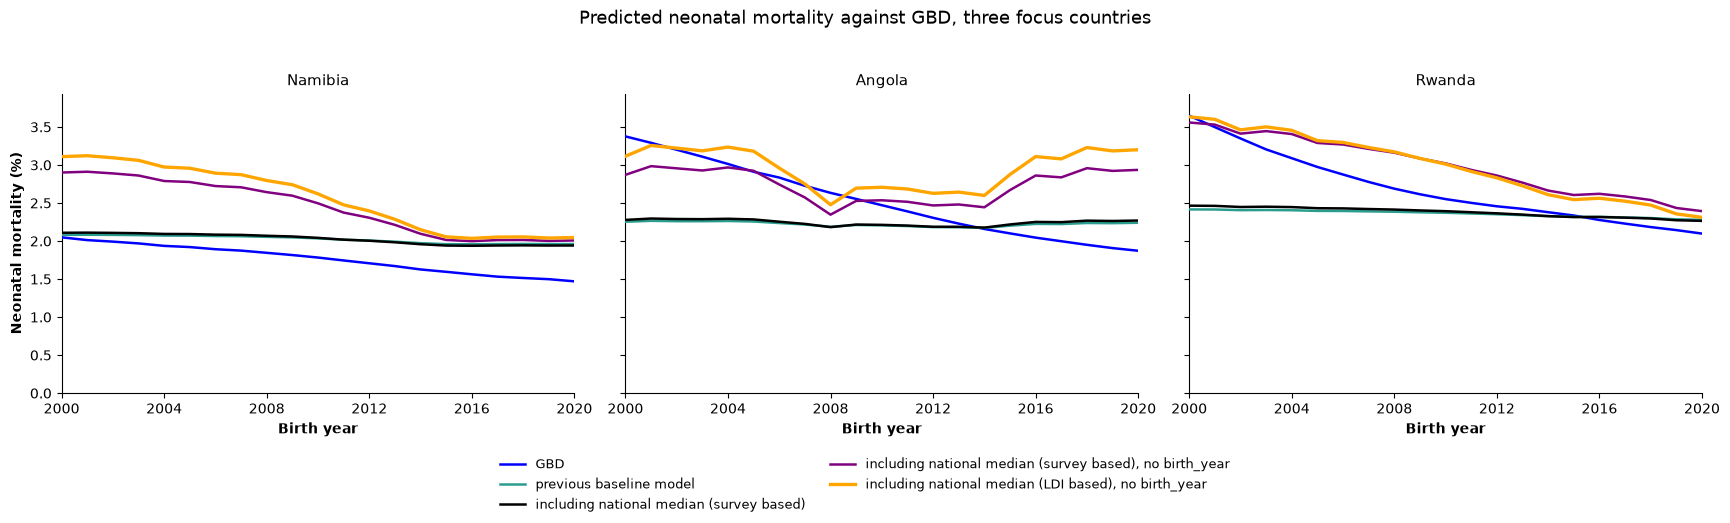

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/gbd_vs_runs_scatter.pdf


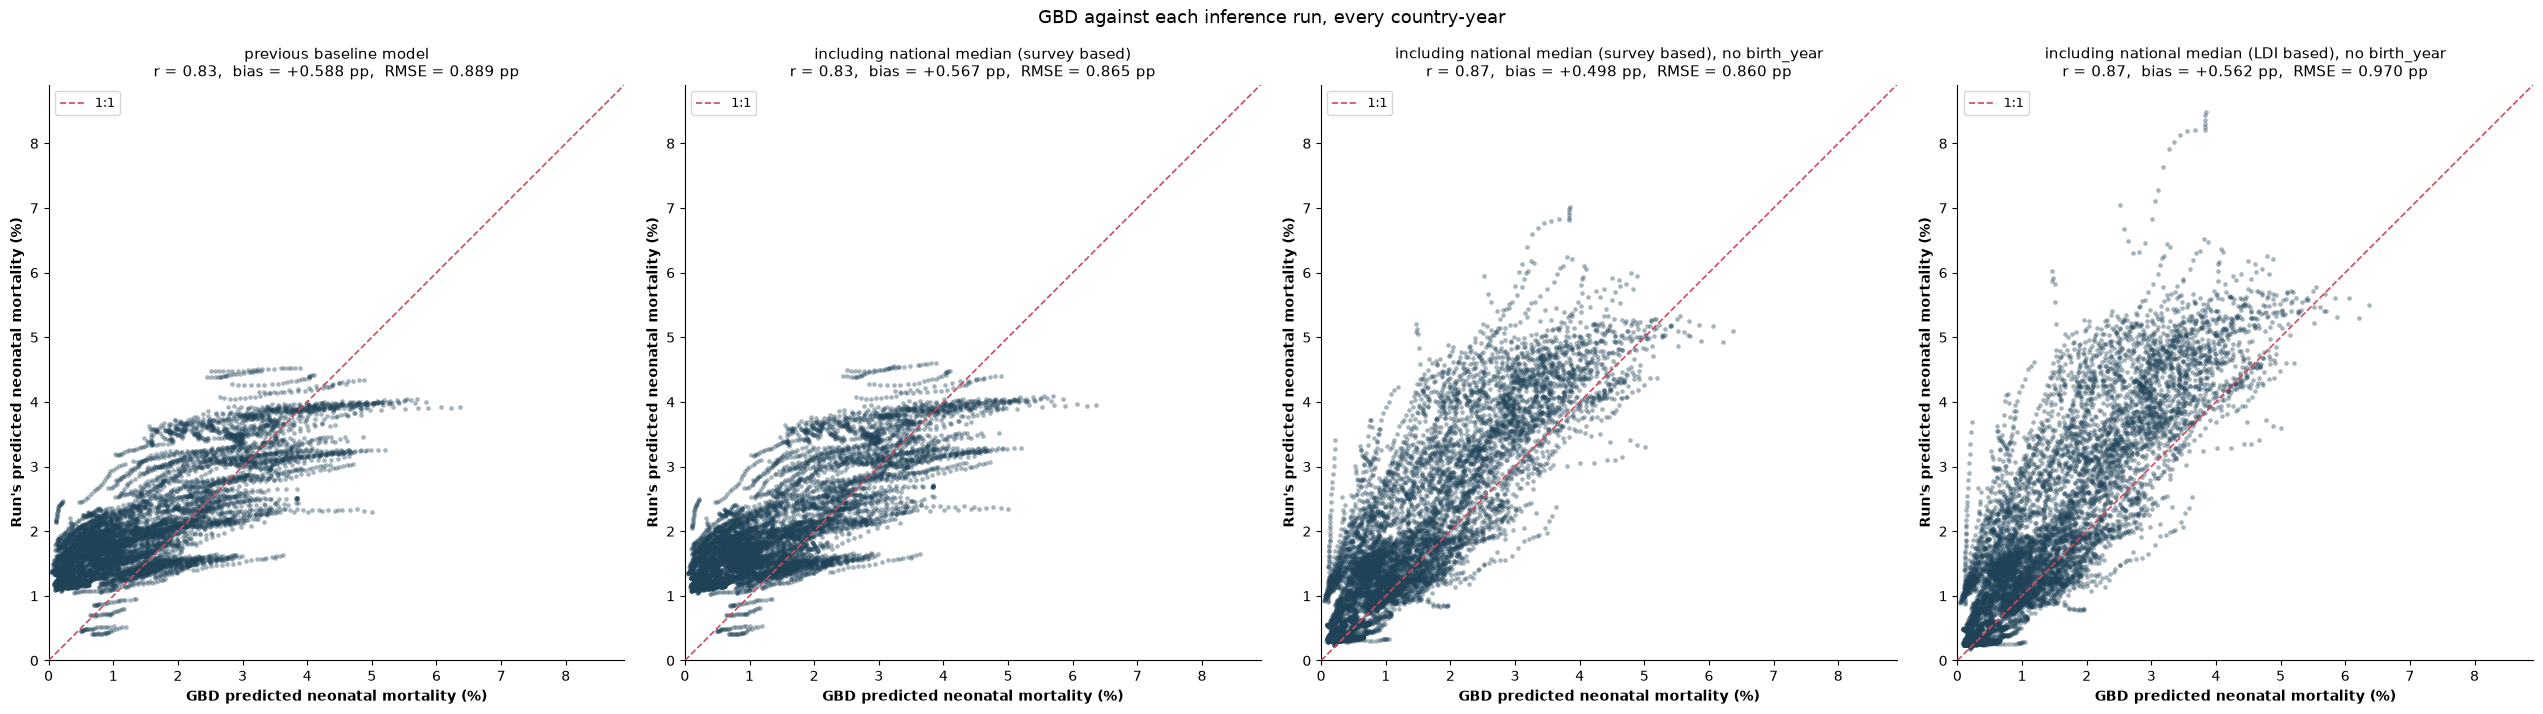


2000 -> 2020 for the focus countries (%):
               gbd_first  gbd_last  i0914_first  i0914_last  i0921_first  i0921_last  i0922a_first  i0922a_last  i0923_first  i0923_last
location_name                                                                                                                           
Namibia             2.05      1.47         2.08        1.96         2.11        1.94          2.90         2.01         3.11        2.05
Angola              3.38      1.87         2.25        2.24         2.28        2.27          2.87         2.94         3.11        3.20
Rwanda              3.65      2.10         2.42        2.28         2.46        2.26          3.56         2.39         3.63        2.31

agreement with GBD over all country-years:
  previous baseline model                                  r 0.827  bias +0.588 pp  RMSE 0.889 pp
  including national median (survey based)                 r 0.834  bias +0.567 pp  RMSE 0.865 pp
  including national median (sur

In [5]:
# Prediction series against GBD, three focus countries ######################
# Same shape as consumption_rt_predictions: one panel per country, birth year
# on x, predicted neonatal mortality on y, one line per source. All series are
# sex-averaged and, for the inference runs, averaged over draws.
#
# 2026_09_22.01 is the run from model 2026_09_21.02 - the first with
# consumption_pd_national_median in the spec.
R4_COUNTRIES = ["Namibia", "Angola", "Rwanda"]
R4_YEARS = (2000, 2020)
# 09_22a takes purple as asked; 09_14 moves to teal, since it held purple and
# two runs in one colour would be unreadable.
R4_SERIES = {
    "gbd": (GBD_FILE, False, "blue", "GBD"),
    "i0914": (INFERENCE_FILE_09_14, True, "#2a9d8f", "previous baseline model"),
    "i0921": (
        INFERENCE_FILE_09_21,
        True,
        "black",
        "including national median (survey based)",
    ),
    "i0922a": (
        INFERENCE_FILE_09_22,
        True,
        "purple",
        "including national median (survey based), no birth_year",
    ),
    "i0923": (
        INFERENCE_FILE_09_23,
        True,
        "orange",
        "including national median (LDI based), no birth_year",
    ),
}
# The newest run carries the heavier line and sits on top.
R4_EMPHASIS = "i0923"


def _r4_mean_draw(frame):
    """Inference files carry either draw columns or a long `draw` column."""
    draw_cols = [c for c in frame.columns if c.startswith("draw_")]
    if draw_cols:
        out = frame[[c for c in frame.columns if "draw_" not in c]].copy()
        out["prevalence"] = frame[draw_cols].mean(axis=1)
        return out
    value_col = "value" if "value" in frame.columns else "prevalence"
    keys = [c for c in ("location_id", "year_id", "sex_id") if c in frame.columns]
    return (
        frame.groupby(keys, as_index=False)[value_col]
        .mean()
        .rename(columns={value_col: "prevalence"})
    )


_r4_key = ["location_id", "year_id", "sex_id"]
r4 = None
for col, (path, is_draws, _c, _l) in R4_SERIES.items():
    f = pd.read_parquet(path).reset_index()
    f = (
        _r4_mean_draw(f).rename(columns={"prevalence": col})
        if is_draws
        else f.rename(columns={"gbd_mean_prevalence": col})
    )
    keys = [k for k in _r4_key if k in f.columns]
    f = f[keys + [col]]
    r4 = f if r4 is None else r4.merge(f, on=keys, how="inner")

r4 = (
    r4.merge(
        locs[["location_id", "location_name"]].drop_duplicates("location_id"),
        on="location_id",
        how="inner",
    )
    .query("year_id >= @R4_YEARS[0] and year_id <= @R4_YEARS[1]")
    .groupby(["location_name", "year_id"], as_index=False)[list(R4_SERIES)]
    .mean()
    .sort_values("year_id")
)
print(
    f"{len(r4):,} country-years across {r4['location_name'].nunique()} countries, "
    f"{R4_YEARS[0]}-{R4_YEARS[1]}, {len(R4_SERIES)} series"
)

# 1. the three focus countries over time #####################################
# One shared y range, computed from the data. Calling set_ylim(0, None) on each
# axis under sharey=True lets the last call win, which sets the range from
# whichever panel happens to be last and draws the taller panels outside the
# axes box - Angola and Rwanda both reach well above Namibia's maximum.
_r4_focus = r4[r4["location_name"].isin(R4_COUNTRIES)]
R4_YMAX = 100 * float(_r4_focus[list(R4_SERIES)].to_numpy().max()) * 1.08

fig, axes = plt.subplots(
    ncols=len(R4_COUNTRIES), figsize=(5.8 * len(R4_COUNTRIES), 5.2), sharey=True
)
axes = np.atleast_1d(axes)
handles, labels = [], []
for ax, country in zip(axes, R4_COUNTRIES):
    block = r4[r4["location_name"] == country].sort_values("year_id")
    for col, (_p, _d, colour, label) in R4_SERIES.items():
        ax.plot(
            block["year_id"],
            100 * block[col],
            color=colour,
            lw=2.4 if col == R4_EMPHASIS else 1.8,
            zorder=4 if col == R4_EMPHASIS else 3,
            label=label,
        )
    ax.set_xlim(*R4_YEARS)
    ax.set_ylim(0, R4_YMAX)
    # Years are integers; the default locator lands on 2002.5, 2007.5 etc.
    ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
    ax.set_xlabel("Birth year", fontweight="bold")
    ax.set_title(country, fontsize=11)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if not handles:
        handles, labels = ax.get_legend_handles_labels()
axes[0].set_ylabel("Neonatal mortality (%)", fontweight="bold")
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=9, frameon=False)
fig.suptitle(
    "Predicted neonatal mortality against GBD, three focus countries", fontsize=13
)
fig.tight_layout(rect=(0, 0.13, 1, 0.95))
plot_path = f"{PLOT_OUTPUT}predictions_four_runs_three_countries.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

# 2. GBD against two runs, every country-year ################################
# All countries, not just the three, and shared square axes with a 1:1 line so
# the two panels are directly comparable.
R4_SCATTER = [
    ("i0914", "previous baseline model"),
    ("i0921", "including national median (survey based)"),
    ("i0922a", "including national median (survey based), no birth_year"),
    ("i0923", "including national median (LDI based), no birth_year"),
]
_r4_max = float(max(r4["gbd"].max(), *(r4[c].max() for c, _ in R4_SCATTER))) * 105
fig, axes = plt.subplots(ncols=len(R4_SCATTER), figsize=(6.4 * len(R4_SCATTER), 6.8))
for ax, (col, title) in zip(np.atleast_1d(axes), R4_SCATTER):
    ax.plot(
        [0, _r4_max],
        [0, _r4_max],
        color="#d1495b",
        lw=1.2,
        ls="--",
        zorder=3,
        label="1:1",
    )
    ax.scatter(
        100 * r4["gbd"],
        100 * r4[col],
        s=11,
        alpha=0.4,
        color="#1f4257",
        linewidths=0,
        zorder=2,
    )
    ax.set_xlim(0, _r4_max)
    ax.set_ylim(0, _r4_max)
    ax.set_aspect("equal")
    ax.set_xlabel("GBD predicted neonatal mortality (%)", fontweight="bold")
    ax.set_ylabel("Run's predicted neonatal mortality (%)", fontweight="bold")
    _diff = r4[col] - r4["gbd"]
    ax.set_title(
        f"{title}\nr = {r4[['gbd', col]].corr().iloc[0, 1]:.2f},  "
        f"bias = {100 * _diff.mean():+.3f} pp,  "
        f"RMSE = {100 * np.sqrt((_diff ** 2).mean()):.3f} pp",
        fontsize=10.5,
    )
    ax.legend(fontsize=9, loc="upper left")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("GBD against each inference run, every country-year", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plot_path = f"{PLOT_OUTPUT}gbd_vs_runs_scatter.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

print("\n2000 -> 2020 for the focus countries (%):")
_ends = (
    r4[r4["location_name"].isin(R4_COUNTRIES)]
    .groupby("location_name")
    .agg(**{f"{c}_{w}": (c, w) for c in R4_SERIES for w in ("first", "last")})
    .loc[R4_COUNTRIES]
)
print((100 * _ends).round(2).to_string())
print("\nagreement with GBD over all country-years:")
for col, title in R4_SCATTER:
    _d = r4[col] - r4["gbd"]
    print(
        f"  {title:56s} r {r4[['gbd', col]].corr().iloc[0, 1]:.3f}  "
        f"bias {100 * _d.mean():+.3f} pp  RMSE {100 * np.sqrt((_d ** 2).mean()):.3f} pp"
    )

In [ ]:
# The same line charts, every level-3 location, straight to pdf ##############
# Same series, colours and labels as predictions_four_runs_three_countries, one
# panel per country instead of three. Pages are grouped by super_region_name -
# a new page starts at each region rather than letting a region run across a
# page boundary - and countries are alphabetical within a region. Nothing is
# drawn in the notebook; every figure is closed after it is written.
#
# Rebuilt from the source files rather than reusing `r4`, because that frame is
# grouped by location_name and no longer carries location_id, which is what
# level and super_region_name join on.
R4A_PER_PAGE = (3, 3)
R4A_PATH = f"{PLOT_OUTPUT}predictions_runs_all_countries.pdf"

_r4a = None
for col, (path, is_draws, _c, _l) in R4_SERIES.items():
    f = pd.read_parquet(path).reset_index()
    f = (
        _r4_mean_draw(f).rename(columns={"prevalence": col})
        if is_draws
        else f.rename(columns={"gbd_mean_prevalence": col})
    )
    keys = [k for k in _r4_key if k in f.columns]
    f = f[keys + [col]]
    _r4a = f if _r4a is None else _r4a.merge(f, on=keys, how="inner")

r4_all = (
    _r4a.merge(
        locs[
            ["location_id", "location_name", "level", "super_region_name"]
        ].drop_duplicates("location_id"),
        on="location_id",
        how="inner",
    )
    .query("level == 3 and year_id >= @R4_YEARS[0] and year_id <= @R4_YEARS[1]")
    # sex-average, then average any remaining strata within a country-year
    .groupby(
        ["super_region_name", "location_name", "year_id"], as_index=False, observed=True
    )[list(R4_SERIES)]
    .mean()
    .sort_values(["super_region_name", "location_name", "year_id"])
)

_countries = r4_all[["super_region_name", "location_name"]].drop_duplicates()
print(
    f"{_countries['location_name'].nunique()} level-3 locations across "
    f"{_countries['super_region_name'].nunique()} super regions, "
    f"{R4_YEARS[0]}-{R4_YEARS[1]}"
)

_nrow, _ncol = R4A_PER_PAGE
_per_page = _nrow * _ncol
_pages = 0
with PdfPages(R4A_PATH) as pdf:
    for region, block in r4_all.groupby("super_region_name", observed=True, sort=True):
        names = sorted(block["location_name"].unique())
        for start in range(0, len(names), _per_page):
            chunk = names[start : start + _per_page]
            fig, axes = plt.subplots(_nrow, _ncol, figsize=(5.0 * _ncol, 4.2 * _nrow))
            axes = np.atleast_1d(axes).ravel()
            handles, labels = [], []
            for ax, country in zip(axes, chunk):
                panel = block[block["location_name"] == country].sort_values("year_id")
                for col, (_p, _d, colour, label) in R4_SERIES.items():
                    ax.plot(
                        panel["year_id"],
                        100 * panel[col],
                        color=colour,
                        lw=2.0 if col == R4_EMPHASIS else 1.5,
                        zorder=4 if col == R4_EMPHASIS else 3,
                        label=label,
                    )
                ax.set_xlim(*R4_YEARS)
                # Years are integers; the default locator lands on 2002.5 etc.
                ax.xaxis.set_major_locator(MaxNLocator(5, integer=True))
                # Per-panel y range: mortality spans an order of magnitude
                # across countries, so a shared range would flatten most panels.
                ax.set_ylim(
                    0, 100 * float(panel[list(R4_SERIES)].to_numpy().max()) * 1.08
                )
                ax.set_title(country, fontsize=10)
                ax.set_axisbelow(True)
                ax.tick_params(labelsize=8)
                for side in ("top", "right"):
                    ax.spines[side].set_visible(False)
                if not handles:
                    handles, labels = ax.get_legend_handles_labels()
            for ax in axes[len(chunk) :]:
                ax.set_visible(False)
            for ax in axes[: len(chunk)]:
                ax.set_xlabel("Birth year", fontweight="bold", fontsize=9)
            for i in range(0, len(chunk), _ncol):
                axes[i].set_ylabel(
                    "Neonatal mortality (%)", fontweight="bold", fontsize=9
                )

            page_of = f" ({start // _per_page + 1} of {-(-len(names) // _per_page)})"
            fig.suptitle(
                f"{region}{page_of if len(names) > _per_page else ''}", fontsize=13
            )
            fig.legend(
                handles, labels, loc="lower center", ncol=2, fontsize=9, frameon=False
            )
            fig.tight_layout(rect=(0, 0.10, 1, 0.95))
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)
            _pages += 1

print(f"Saved {R4A_PATH} ({_pages} pages)")

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/median_birth_year_collision.pdf
  consumption_median_RT: SD between 0.5544, within 0.1867
  within-country growth +0.02137/yr, R2 against birth_year 0.645
  off-trend residual = 3.9% of total variance
  observed within-country mortality trend -0.02263/yr; income at beta=-0.57601 delivers -0.01231/yr (54%)


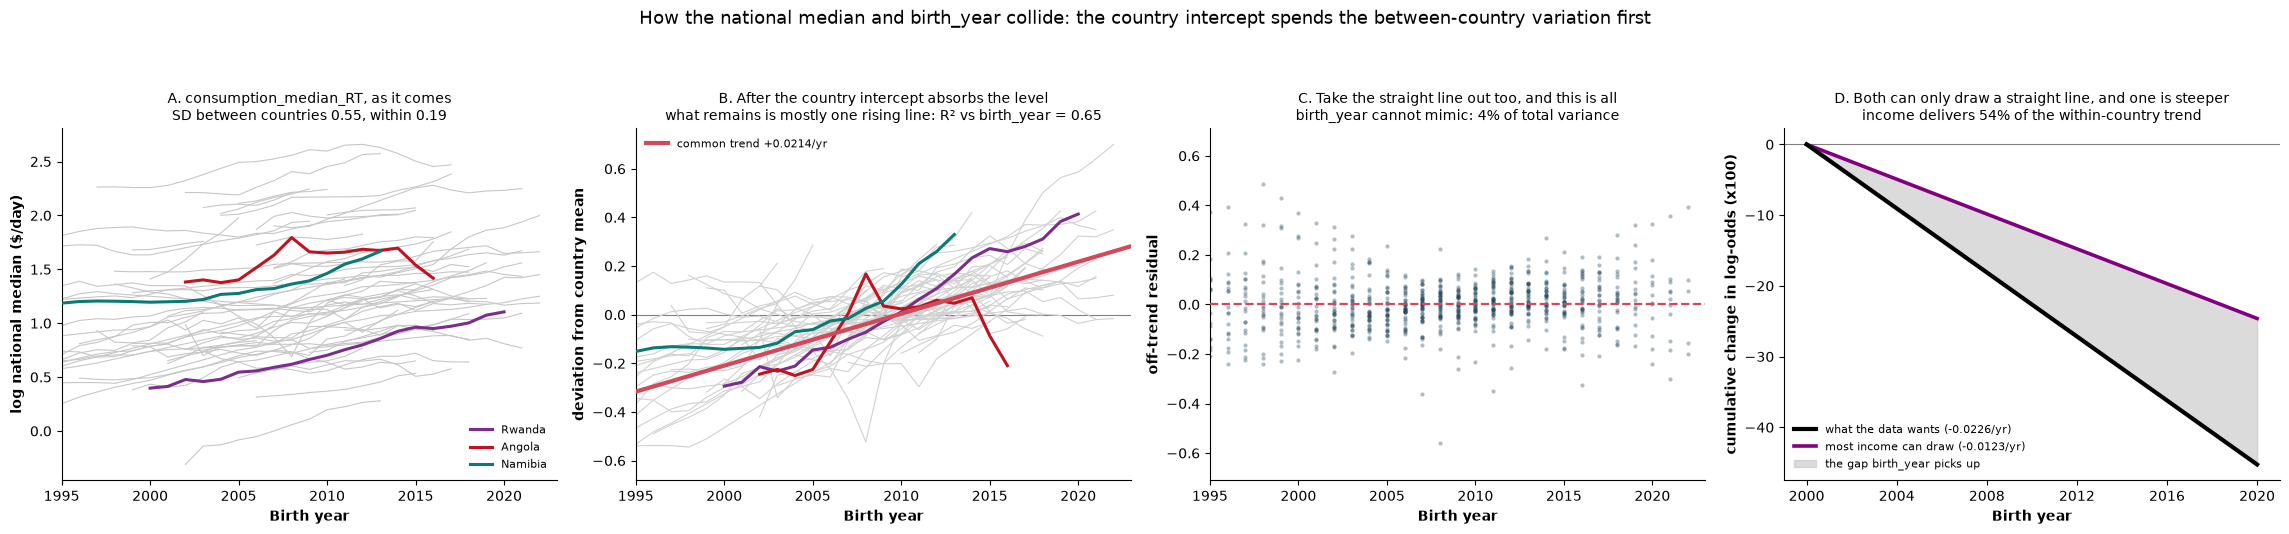

In [ ]:
# Why the national median and birth_year collide #############################
# The puzzle: the median varies both between countries AND over time, while
# birth_year varies only over time, so it is not obvious how birth_year can
# take the median's coefficient away.
#
# The answer is that the model never gets to use the between-country part. The
# country random intercept absorbs it first. Whatever the median explains
# ACROSS countries is already explained by "which country is this", for free
# and without a functional form. So the four panels walk the median's variation
# through the model in the order the model actually consumes it, and show how
# little is left by the time birth_year enters.
CO2_TERM = "consumption_median_RT"
CO2_FOCUS = {"Rwanda": "#7b2d8b", "Angola": "#c1121f", "Namibia": "#0b7a75"}
CO2_YEARS = (1995, 2023)

_co2 = df_raw[df_raw[CO2_TERM] > 0].dropna(
    subset=["birth_year", "neonatal_mortality", CO2_TERM]
)
co2 = (
    _co2.groupby(["ihme_loc_id", "location_name", "birth_year"], observed=True)
    .agg(
        x=(CO2_TERM, "first"),
        deaths=("neonatal_mortality", "sum"),
        n=("neonatal_mortality", "size"),
    )
    .reset_index()
)
co2 = co2[co2["n"] >= 50].copy()
co2["lx"] = np.log(co2["x"])
# Haldane-Anscombe so zero-death country-years survive the logit
co2["logit"] = np.log((co2["deaths"] + 0.5) / (co2["n"] - co2["deaths"] + 0.5))

# Birth-weighted demeaning within country - this is what a country fixed effect
# (and, near enough, the country random intercept) actually removes. birth_year
# has to be demeaned TOO: countries are surveyed in different year windows, so
# raw birth_year still carries between-country information. Leaving it raw
# attenuates both the slope and the R2 below and understates the collision.
_wt = co2.groupby("ihme_loc_id")["n"].transform("sum")
for _c in ("lx", "logit", "birth_year"):
    co2[f"{_c}_w"] = (
        co2[_c]
        - (co2[_c] * co2["n"]).groupby(co2["ihme_loc_id"]).transform("sum") / _wt
    )

# Trend of the demeaned series on demeaned birth_year: this IS the collision.
# The slope is how fast income grows within a country; R2 is how much of the
# median's surviving variation is indistinguishable from a straight line in time.
_fit = np.polyfit(co2["birth_year_w"], co2["lx_w"], 1, w=np.sqrt(co2["n"]))
_g = _fit[0]
_pred = np.polyval(_fit, co2["birth_year_w"])
_r2 = 1 - np.average((co2["lx_w"] - _pred) ** 2, weights=co2["n"]) / np.average(
    (co2["lx_w"] - np.average(co2["lx_w"], weights=co2["n"])) ** 2, weights=co2["n"]
)
_sd_b = co2.groupby("ihme_loc_id")["lx"].mean().std(ddof=1)
_sd_w = co2["lx_w"].std(ddof=1)
_resid = co2["lx_w"] - _pred
_share_off = np.var(_resid) / (_sd_b**2 + _sd_w**2)

# Observed within-country trend in mortality, and what income alone can draw
_mfit = np.polyfit(co2["birth_year_w"], co2["logit_w"], 1, w=np.sqrt(co2["n"]))
CO2_OBS_TREND = _mfit[0]
CO2_BETA = -0.57601  # RESULTS_09_23 coefficient on consumption_median_RT
CO2_INCOME_TREND = CO2_BETA * _g

fig, axes = plt.subplots(ncols=4, figsize=(23, 5.4))

# --- A: the raw series -------------------------------------------------------
ax = axes[0]
for loc, grp in co2.groupby("location_name", observed=True):
    ax.plot(grp["birth_year"], grp["lx"], color="0.78", lw=0.8, zorder=2)
for loc, colour in CO2_FOCUS.items():
    grp = co2[co2["location_name"] == loc].sort_values("birth_year")
    ax.plot(grp["birth_year"], grp["lx"], color=colour, lw=2.2, zorder=4, label=loc)
ax.set_title(
    f"A. {CO2_TERM}, as it comes\n"
    f"SD between countries {_sd_b:.2f}, within {_sd_w:.2f}",
    fontsize=10,
)
ax.set_ylabel("log national median ($/day)", fontweight="bold")
ax.legend(fontsize=8, frameon=False, loc="lower right")

# --- B: what the country random intercept takes ------------------------------
ax = axes[1]
for loc, grp in co2.groupby("location_name", observed=True):
    ax.plot(grp["birth_year"], grp["lx_w"], color="0.82", lw=0.8, zorder=2)
for loc, colour in CO2_FOCUS.items():
    grp = co2[co2["location_name"] == loc].sort_values("birth_year")
    ax.plot(grp["birth_year"], grp["lx_w"], color=colour, lw=2.2, zorder=4)
_xs = np.linspace(*CO2_YEARS, 50)
# Drawn in raw-year coordinates for readability: the fitted within-country
# slope, through the birth-weighted centroid (where lx_w averages to zero).
_x0 = np.average(co2["birth_year"], weights=co2["n"])
ax.plot(
    _xs,
    _g * (_xs - _x0),
    color="#d1495b",
    lw=3,
    zorder=5,
    label=f"common trend {_g:+.4f}/yr",
)
ax.axhline(0, color="0.5", lw=0.8, zorder=1)
ax.set_title(
    "B. After the country intercept absorbs the level\n"
    f"what remains is mostly one rising line: R² vs birth_year = {_r2:.2f}",
    fontsize=10,
)
ax.set_ylabel("deviation from country mean", fontweight="bold")
ax.legend(fontsize=8, frameon=False, loc="upper left")

# --- C: what is left to tell the two terms apart -----------------------------
ax = axes[2]
ax.scatter(
    co2["birth_year"], _resid, s=9, alpha=0.35, color="#1f4257", linewidths=0, zorder=2
)
ax.axhline(0, color="#d1495b", lw=1.6, ls="--", zorder=3)
ax.set_ylim(-max(abs(_resid)) * 1.05, max(abs(_resid)) * 1.05)
ax.set_title(
    "C. Take the straight line out too, and this is all\n"
    f"birth_year cannot mimic: {100 * _share_off:.0f}% of total variance",
    fontsize=10,
)
ax.set_ylabel("off-trend residual", fontweight="bold")

# --- D: the collision, in the units that matter ------------------------------
# Both terms can only draw a straight line in time once country is absorbed.
# birth_year's slope is free, so it takes whatever the data wants; income's
# slope is pinned to beta x (income growth) and comes up short.
ax = axes[3]
_yy = np.arange(2000, 2021)
_t = _yy - _yy[0]
ax.plot(
    _yy,
    100 * CO2_OBS_TREND * _t,
    color="black",
    lw=3,
    zorder=4,
    label=f"what the data wants ({CO2_OBS_TREND:+.4f}/yr)",
)
ax.plot(
    _yy,
    100 * CO2_INCOME_TREND * _t,
    color="purple",
    lw=2.6,
    zorder=3,
    label=f"most income can draw ({CO2_INCOME_TREND:+.4f}/yr)",
)
ax.fill_between(
    _yy,
    100 * CO2_INCOME_TREND * _t,
    100 * CO2_OBS_TREND * _t,
    color="0.75",
    alpha=0.55,
    zorder=2,
    label="the gap birth_year picks up",
)
ax.axhline(0, color="0.5", lw=0.8, zorder=1)
ax.set_title(
    "D. Both can only draw a straight line, and one is steeper\n"
    f"income delivers {100 * CO2_INCOME_TREND / CO2_OBS_TREND:.0f}% of the "
    "within-country trend",
    fontsize=10,
)
ax.set_ylabel("cumulative change in log-odds (x100)", fontweight="bold")
ax.legend(fontsize=8, frameon=False, loc="lower left")

for ax in axes:
    ax.set_xlabel("Birth year", fontweight="bold")
    ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
for ax in axes[:3]:
    ax.set_xlim(*CO2_YEARS)

fig.suptitle(
    "How the national median and birth_year collide: the country intercept "
    "spends the between-country variation first",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plot_path = f"{PLOT_OUTPUT}median_birth_year_collision.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
print(
    f"  {CO2_TERM}: SD between {_sd_b:.4f}, within {_sd_w:.4f}\n"
    f"  within-country growth {_g:+.5f}/yr, R2 against birth_year {_r2:.3f}\n"
    f"  off-trend residual = {100 * _share_off:.1f}% of total variance\n"
    f"  observed within-country mortality trend {CO2_OBS_TREND:+.5f}/yr; "
    f"income at beta={CO2_BETA} delivers {CO2_INCOME_TREND:+.5f}/yr "
    f"({100 * CO2_INCOME_TREND / CO2_OBS_TREND:.0f}%)"
)
plt.show()